# start2impact University | Progetto Advanced Analytics

Ti diamo il benvenuto nel notebook del progetto del Corso Advanced Analytics!

Prima di tutto bisogna importare una serie di librerie core, che saranno quelle principali per rispondere alle domande del progetto:

In [1]:
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt

Per usare il tuo Google Drive con Colab, bisogna montarlo tramite il seguente comando. Dovrebbe chiederti l'accesso tramite il tuo account Google, concediglielo e seleziona tutte le spunte disponibili.

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PATH = '/content/drive/MyDrive/start2impact/advanced_analytics/'
except ImportError:
    PATH = '../data/'

Dopodiché puoi partire con l'importazione del dataset **supermarket sales**, il primo che ti servirà: dovresti averlo già uploadato nel tuo Drive, inserisci la location dove lo hai salvato andando a sostituire il placeholder *{PATH_AL_FILE_SUL_TUO_DRIVE}*, così da importarlo nell'ambiente di lavoro:

In [3]:
regression_raw_dataset = pd.read_csv(PATH + 'supermarket_sales.csv', encoding='windows-1254')

# Esplorazione del dataset

**In questa breve sezione andrai a visualizzare il dataset in forma tabellare**, così da averne una rappresentazione più intuitiva e comprendere meglio con che tipologia di dato hai a che fare. Per semplicità si mostrano solo le prime 100 occorrenze.

In [4]:
regression_raw_dataset.head(100)

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,594-34-4444,A,Yangon,Normal,Male,Electronic accessories,97.16,1,4.8580,102.0180,3/8/2019,20:38,Ewallet,97.16,4.761905,4.8580,7.2
96,766-85-7061,B,Mandalay,Normal,Male,Health and beauty,87.87,10,43.9350,922.6350,3/29/2019,10:25,Ewallet,878.70,4.761905,43.9350,5.1
97,871-39-9221,C,Naypyitaw,Normal,Female,Electronic accessories,12.45,6,3.7350,78.4350,2/9/2019,13:11,Cash,74.70,4.761905,3.7350,4.1
98,865-92-6136,A,Yangon,Normal,Male,Food and beverages,52.75,3,7.9125,166.1625,3/23/2019,10:16,Ewallet,158.25,4.761905,7.9125,9.3


Vai quindi a vedere più nel dettaglio quali sono i metadati principali delle colonne del dataset:

In [5]:
regression_raw_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   str    
 1   Branch                   1000 non-null   str    
 2   City                     1000 non-null   str    
 3   Customer type            1000 non-null   str    
 4   Gender                   1000 non-null   str    
 5   Product line             1000 non-null   str    
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   str    
 11  Time                     1000 non-null   str    
 12  Payment                  1000 non-null   str    
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  1000 non-nu

Da questo puoi già vedere che non ci sono valori nulli, per cui non dovrai usare nessuna strategia per fillarli, altri valori invece sono categorici e quindi bisognerà usare una strategia per codificarli; insomma hai già un po' di informazioni di massima sul dato!
Alcune colonne risultano poco utili ai fini dell'analisi per la predizione e quindi vanno semplicemente eliminate, come per esempio l'ID della fattura, la data della vendita, l'orario e un altro paio:

In [6]:
regression_dataset = regression_raw_dataset.drop(columns=['Invoice ID', 'Tax 5%', 'Total', 'Date', 'Time', 'cogs', 'gross margin percentage'])

Puoi quindi vedere che alcune colonne sono state rimosse e adesso hai solo quelle che effettivamente sono utili ai fini dello sviluppo del modello:

In [7]:
regression_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Branch         1000 non-null   str    
 1   City           1000 non-null   str    
 2   Customer type  1000 non-null   str    
 3   Gender         1000 non-null   str    
 4   Product line   1000 non-null   str    
 5   Unit price     1000 non-null   float64
 6   Quantity       1000 non-null   int64  
 7   Payment        1000 non-null   str    
 8   gross income   1000 non-null   float64
 9   Rating         1000 non-null   float64
dtypes: float64(3), int64(1), str(6)
memory usage: 78.3 KB


# Media, mediana, moda e deviazione standard

Si parte con un esercizio molto semplice, in cui ti chiedo di **calcolare usando numpy la media, la mediana e la moda della colonna su cui andrai a fare predizioni (la label), ovvero Rating**. Ai fini del progetto la colonna Rating acquisisce un significato differente rispetto a quello originale del dataset: essa dà una valutazione alla transazione in base alla redditività della stessa e quindi ti dice quanto è stata proficua la stessa per la catena di supermercati.
Questo ti darà una prima idea di sintesi sui rating assegnati ai vari ordini:

In [8]:
rating = regression_dataset['Rating'].to_numpy()

media = np.mean(rating)
mediana = np.median(rating)
# numpy non ha la moda, la ricavo contando i valori
valori, conteggi = np.unique(rating, return_counts=True)
moda = valori[np.argmax(conteggi)]

print('media =', round(media, 3))
print('mediana =', mediana)
print('moda =', moda, '(compare', conteggi.max(), 'volte)')

media = 6.973
mediana = 7.0
moda = 6.0 (compare 26 volte)


Come hai visto durante il Corso, la **deviazione** è una importantissima misura di "sparsità" dei dati, ed è una informazione che è molto utile da ottenere sulla label. Ti chiedo quindi di calcolarla, sempre usando Numpy:

In [9]:
dev_std = np.std(rating)
print('deviazione standard =', round(dev_std, 3))

deviazione standard = 1.718


# Come sono distribuiti i valori della label

A questo punto andiamo a vedere come sono graficamente distribuiti i dati:

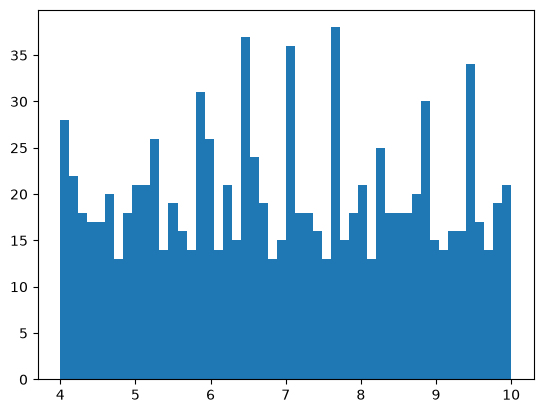

In [10]:
plt.hist(regression_dataset['Rating'], 50)
plt.show()

Come puoi vedere, la distribuzione dei rating è più o meno uniforme e non c'è skewness.

Il discorso è invece diverso per l'utile lordo:

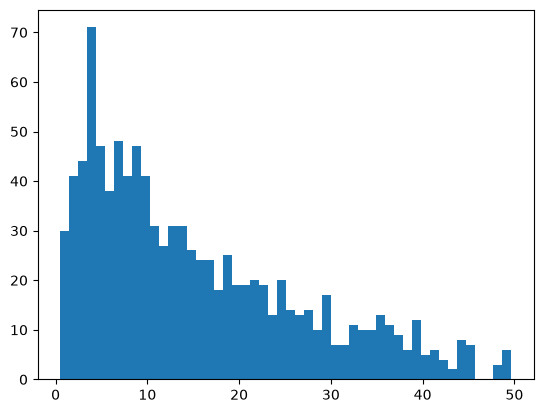

In [11]:
plt.hist(regression_dataset['gross income'], 50)
plt.show()

Come puoi vedere, qui la skewness c'è eccome e la maggioranza degli ordini sembra avere un income lordo basso.
Qual è, quindi, il valore di questa skewness esattamente? Tocca a te scoprirlo nella prossima cella!

Un piccolo consiglio: farlo con Numpy non è il modo più semplice!

In [12]:
from scipy.stats import skew

print('skewness gross income =', round(skew(regression_dataset['gross income']), 3))

skewness gross income = 0.891


# Encoding delle variabili categoriche

Come avrai sicuramente notato, ci sono delle variabili (come "Branch", "City", "Customer type", "Gender", "Product line" e "Payment") che non sono numeriche e che quindi non possono essere direttamente masticate dagli algoritmi che andrai a utilizzare più tardi.
Ricordi le **tecniche per effettuarne l'enconding**? Questo è il momento di usarle per trasformarle in vettori!

In [13]:
# Branch e City sono la stessa informazione (A = Yangon, B = Mandalay, C = Naypyitaw)
pd.crosstab(regression_dataset['Branch'], regression_dataset['City'])

City,Mandalay,Naypyitaw,Yangon
Branch,,,
A,0,0,340
B,332,0,0
C,0,328,0


In [14]:
from sklearn.preprocessing import OneHotEncoder

# tengo solo City
regression_dataset = regression_dataset.drop(columns=['Branch'])
categoriche = ['City', 'Customer type', 'Gender', 'Product line', 'Payment']

# drop='first' per non avere colonne ridondanti
encoder = OneHotEncoder(drop='first', sparse_output=False, dtype=int)
encoded = encoder.fit_transform(regression_dataset[categoriche])
encoded = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(categoriche), index=regression_dataset.index)

regression_dataset = pd.concat([regression_dataset.drop(columns=categoriche), encoded], axis=1)
regression_dataset.head()

,Unit price,Quantity,gross income,Rating,City_Naypyitaw,City_Yangon,Customer type_Normal,Gender_Male,Product line_Fashion accessories,Product line_Food and beverages,Product line_Health and beauty,Product line_Home and lifestyle,Product line_Sports and travel,Payment_Credit card,Payment_Ewallet
0,74.69,7,26.1415,9.1,0,1,0,0,0,0,1,0,0,0,1
1,15.28,5,3.8200,9.6,1,0,1,0,0,0,0,0,0,0,0
2,46.33,7,16.2155,7.4,0,1,1,1,0,0,0,1,0,1,0
3,58.22,8,23.2880,8.4,0,1,0,1,0,0,1,0,0,0,1
4,86.31,7,30.2085,5.3,0,1,1,1,0,0,0,0,1,0,1


# Feature Scaling

Nel dataset ci sono alcune feature che potrebbero essere standardizzate/normalizzate: quelle più evidenti sono sicuramente il prezzo del singolo oggetto, ovvero "Unit price", e "gross income" che come hai visto ha una grossa skewness. Questo dovrebbe migliorare la performance dei modelli che andrai a costruire a brevissimo, per cui ti chiedo di procedere in tal senso con la **standardizzazione**:

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
regression_dataset[['Unit price', 'gross income']] = scaler.fit_transform(regression_dataset[['Unit price', 'gross income']])
regression_dataset[['Unit price', 'gross income']].describe().round(2)

,Unit price,gross income
count,1000.00,1000.00
mean,-0.00,0.00
std,1.00,1.00
min,-1.72,-1.27
25%,-0.86,-0.81
50%,-0.02,-0.28
75%,0.84,0.60
max,1.67,2.93


# Train e Test Split

Bene, è quindi giunta l'ora di affrontare l'ultima fase prima di allenare un modello di machine learning: l**o split fra training e test set**!
Per un primo approccio ti suggeriamo di usare una ratio 80:20 o 70:30, che il più delle volte funzionano bene.

Ti chiediamo di chiamare le feature di train, le feature di test, la label di train e le label di test rispettivamente con i nomi *X_train*, *X_test*, *y_train* e *y_test*:

In [16]:
from sklearn.model_selection import train_test_split

X = regression_dataset.drop(columns=['Rating'])
y = regression_dataset['Rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(800, 14) (200, 14)


# Linear Regression

Ora è giunto il momento di predire i **Rating** usando il modello più semplice che hai visto, ovvero la linear regression!
Ti chiediamo di chiamare il modello *regressor*.

Procedi pure nella cella che segue:

In [17]:
from sklearn.linear_model import LinearRegression

regressor = LinearRegression()
regressor.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[ 0.16, 0.06,-0.31,...,-0.07, 0.08, 0.05]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['Unit price','Quantity','gross income',..., 'Product line_Sports and travel','Payment_Credit card','Payment_Ewallet']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.427
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(14)


Adesso che il training è avvenuto è il momento di valutare come questo performa. Le metriche che prendiamo in considerazione, che sono le principali per la regressione lineare, sono **il mean squadred error e il mean absolute error**. Ti chiediamo di calcolarle (sempre usando sklearn), avendo cura di chiamarle rispettivamente *MSE* e *MAE*. Punta a renderle il più vicine allo zero possibile, perché il modello è più di qualità quanto più queste sono zero:

In [18]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

y_pred = regressor.predict(X_test)
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)

print('MSE =', MSE, '\nMAE =', MAE)

MSE = 3.110187291026073 
MAE = 1.5229214208487525


Prima di dire se è tanto o poco, lo confronto con il modello più stupido possibile: rispondere sempre con la media dei rating del training set.

In [19]:
baseline = np.full(len(y_test), y_train.mean())
print('baseline MSE =', mean_squared_error(y_test, baseline), '\nbaseline MAE =', mean_absolute_error(y_test, baseline))

# correlazione del Rating con le altre colonne numeriche
regression_raw_dataset.select_dtypes('number').corr()['Rating'].drop('Rating').round(3)

baseline MSE = 3.0784863906249997 
baseline MAE = 1.5168012499999997


Unit price                -0.009
Quantity                  -0.016
Tax 5%                    -0.036
Total                     -0.036
cogs                      -0.036
gross margin percentage      NaN
gross income              -0.036
Name: Rating, dtype: float64

La regressione lineare fa leggermente **peggio** della baseline. Il motivo si vede dalle correlazioni: il Rating non è legato a nessuna colonna del dataset (tutte sotto 0.04 in valore assoluto). Con queste feature non c'è niente da imparare, e l'MSE non può scendere molto sotto la varianza del Rating (circa 3).

# Polynomial Regression

Prova in questa sezione a lavorare in modo simile a quanto fatto per la linear regression, ma usando la polynomial regression, che è sicuramente più potente della prima.

Come prima, ti chiediamo di chiamare *regressor* il modello e *poly_regressor* l'oggetto relativo alle feature polinomiali:

In [20]:
from sklearn.preprocessing import PolynomialFeatures

poly_regressor = PolynomialFeatures(degree=2)
X_train_poly = poly_regressor.fit_transform(X_train)
X_test_poly = poly_regressor.transform(X_test)

regressor = LinearRegression()
regressor.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](120,)","[ 0. ,-2.13, 0.27,...,-0.17, 0. ,-0.39]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.803
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,120
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(95)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](120,)","[962.58,244.41,107.92,..., 0. , 0. , 0. ]"


Come cambiano le performance? C'è effettivamente un miglioramento nell'MSE e nell'MAE?

In [21]:
y_pred = regressor.predict(X_test_poly)
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)

print('MSE =', MSE, '\nMAE =', MAE)

MSE = 3.4526188576441204 
MAE = 1.5692996530611774


**Risposta:** no, peggiora. Con il grado 2 le feature passano da 14 a 120: il modello è più flessibile ma, visto che il Rating non dipende da queste variabili, usa la flessibilità per adattarsi al rumore del training set (overfitting). Il problema qui non è il modello, sono i dati.

# Logistic Regression

In questa sezione si cambia dataset, in quanto cambia la natura del problema: si passa infatti a un problema di classificazione, in cui andrai a valutare la qualità di alcune mele destinate alla catena di supermercati per decidere quali sono le mele di qualità migliore.

La prima cosa è da fare è** importare il nuovo dataset**, ovvero apple_quality, che questa volta ti chiediamo di fare in autonomia, chiamando il dataset *classification_dataset*:

In [22]:
classification_dataset = pd.read_csv(PATH + 'apple_quality.csv')

Ti suggeriamo quindi  di printare le prime 50 righe...

In [23]:
classification_dataset.head(50)

,A_id,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,0.0,-3.970049,-2.512336,5.346330,-1.012009,1.844900,0.329840,-0.491590483,good
1,1.0,-1.195217,-2.839257,3.664059,1.588232,0.853286,0.867530,-0.722809367,good
2,2.0,-0.292024,-1.351282,-1.738429,-0.342616,2.838636,-0.038033,2.621636473,bad
3,3.0,-0.657196,-2.271627,1.324874,-0.097875,3.637970,-3.413761,0.790723217,good
4,4.0,1.364217,-1.296612,-0.384658,-0.553006,3.030874,-1.303849,0.501984036,good
5,5.0,-3.425400,-1.409082,-1.913511,-0.555775,-3.853071,1.914616,-2.981523169,bad
6,6.0,1.331606,1.635956,0.875974,-1.677798,3.106344,-1.847417,2.414170509,good
7,7.0,-1.995462,-0.428958,1.530644,-0.742972,0.158834,0.974438,-1.470125066,good
8,8.0,-3.867632,-3.734514,0.986429,-1.207655,2.292873,4.080921,-4.871904758,bad
9,9.0,-0.727983,-0.442820,-4.092223,0.597513,0.393714,1.620857,2.185607723,bad


... e dei metadati delle colonne:

In [24]:
classification_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 4001 entries, 0 to 4000
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   A_id         4000 non-null   float64
 1   Size         4000 non-null   float64
 2   Weight       4000 non-null   float64
 3   Sweetness    4000 non-null   float64
 4   Crunchiness  4000 non-null   float64
 5   Juiciness    4000 non-null   float64
 6   Ripeness     4000 non-null   float64
 7   Acidity      4001 non-null   str    
 8   Quality      4000 non-null   str    
dtypes: float64(7), str(2)
memory usage: 281.4 KB


Acidity risulta di tipo testo e non numerico, e c'è una riga in più (4001 invece di 4000). Guardando la fine del file:

In [25]:
classification_dataset.tail(3)

,A_id,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
3998,3998.0,-4.008004,-1.779337,2.366397,-0.200329,2.161435,0.214488,-2.229719806,good
3999,3999.0,0.278540,-1.715505,0.121217,-1.154075,1.266677,-0.776571,1.599796456,good
4000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Created_by_Nidula_Elgiriyewithana,NaN


L'ultima riga non è una mela: è la firma dell'autore del dataset, finita nella colonna Acidity. La tolgo e riconverto Acidity in numero. Tolgo anche A_id, che è solo un identificativo e non deve finire tra le feature.

In [26]:
classification_dataset = classification_dataset.dropna(subset=['Quality'])
classification_dataset['Acidity'] = classification_dataset['Acidity'].astype(float)
classification_dataset = classification_dataset.drop(columns=['A_id'])

classification_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Size         4000 non-null   float64
 1   Weight       4000 non-null   float64
 2   Sweetness    4000 non-null   float64
 3   Crunchiness  4000 non-null   float64
 4   Juiciness    4000 non-null   float64
 5   Ripeness     4000 non-null   float64
 6   Acidity      4000 non-null   float64
 7   Quality      4000 non-null   str    
dtypes: float64(7), str(1)
memory usage: 250.1 KB


Come puoi vedere, il dataset è già pulito e quasi tutte le colonne sono numeriche. L'unica a non esserlo è proprio la label, che va encodata:

In [27]:
# good = 1, bad = 0
classification_dataset['Quality'] = classification_dataset['Quality'].map({'good': 1, 'bad': 0})
classification_dataset['Quality'].value_counts()

Quality
1    2004
0    1996
Name: count, dtype: int64

Bisogna poi ri-effettuare la divisione fra porzione di addestramento e porzione di test, usando la nomenclatura vista in precedenza:

In [28]:
X = classification_dataset.drop(columns=['Quality'])
y = classification_dataset['Quality']

# stratify per avere la stessa proporzione good/bad in train e test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(3200, 7) (800, 7)


Puoi finalmente usare la logistic regression per allenare il modello vero e proprio, che ti chiedo di chiamare *logistic_regressor*:

In [29]:
from sklearn.linear_model import LogisticRegression

logistic_regressor = LogisticRegression(max_iter=1000)
logistic_regressor.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Una metrica che ti permette subito di valutare la bontà del modello, come saprai, è l'***F1 score***, che dovrebbe essere idealmente superiore a 0.80. Cerca anche di massimizzare la media della precision e del recall, che idealmente dovrebbero anch'essi essere superiori a 0.80:

In [30]:
from sklearn.metrics import classification_report

y_predict_test = logistic_regressor.predict(X_test)

print(classification_report(y_test, y_predict_test))

              precision    recall  f1-score   support

           0       0.76      0.71      0.73       399
           1       0.73      0.77      0.75       401

    accuracy                           0.74       800
   macro avg       0.74      0.74      0.74       800
weighted avg       0.74      0.74      0.74       800



F1 di 0.73 e 0.75 sulle due classi (0.74 in media), sotto l'obiettivo di 0.80. La logistic regression traccia un confine lineare tra mele buone e cattive, e probabilmente non basta. Provo ad aggiungere feature polinomiali, come fatto prima con la regressione (con grado 2 arrivavo a circa 0.85, con grado 3 va meglio):

In [31]:
from sklearn.pipeline import make_pipeline

logistic_regressor = make_pipeline(PolynomialFeatures(degree=3), StandardScaler(), LogisticRegression(max_iter=5000))
logistic_regressor.fit(X_train, y_train)

y_predict_test = logistic_regressor.predict(X_test)
print(classification_report(y_test, y_predict_test))

              precision    recall  f1-score   support

           0       0.88      0.87      0.88       399
           1       0.88      0.88      0.88       401

    accuracy                           0.88       800
   macro avg       0.88      0.88      0.88       800
weighted avg       0.88      0.88      0.88       800



Ora è intessante andare a "disegnare" la **confusion matrix**, che ti mostra quali sono le categorie su cui il modello che hai costruito è "bravo" e su quali no, così da eventualmente avere delle informazioni in più per migliorarlo. Prova a farlo in autonomia usando scikit-learn:

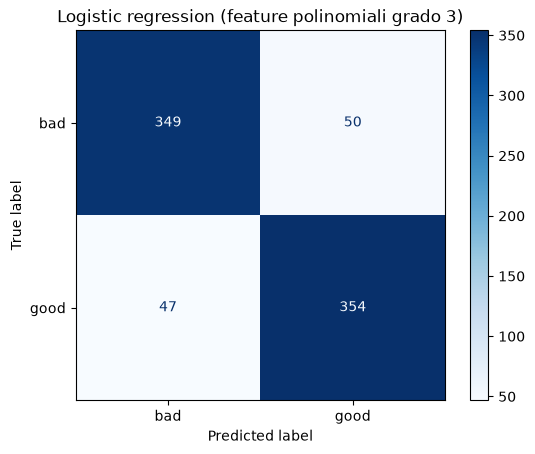

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_logistic = confusion_matrix(y_test, y_predict_test)
ConfusionMatrixDisplay(cm_logistic, display_labels=['bad', 'good']).plot(cmap='Blues')
plt.title('Logistic regression (feature polinomiali grado 3)')
plt.show()

# Decision Tree

**Puoi provare a usare un decision tree per capire se può migliorare le prestazioni del modello basato su logistic regression.** Generalmente, come visto durante la parte teorica del Corso, i decision tree sono più potenti, ma scoprilo costruendone uno!

Il procedimento non è dissimile da quelli usati in precedenza, quindi procedi pure al training:

In [33]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

y_predict_tree = tree.predict(X_test)
print(classification_report(y_test, y_predict_tree))

              precision    recall  f1-score   support

           0       0.80      0.79      0.80       399
           1       0.80      0.81      0.80       401

    accuracy                           0.80       800
   macro avg       0.80      0.80      0.80       800
weighted avg       0.80      0.80      0.80       800



E poi alla costruzione della confusion matrix:

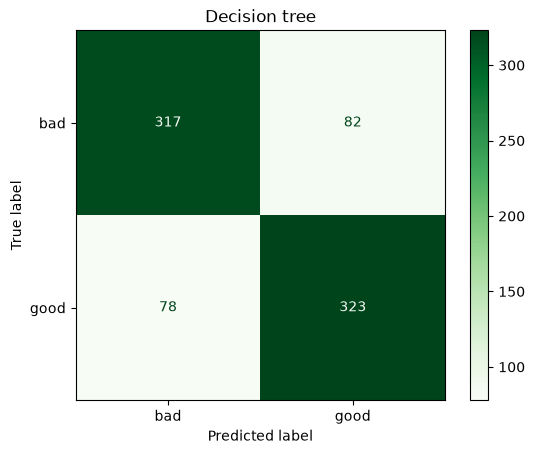

errori decision tree: 160 su 800
errori logistic (grado 3): 97 su 800


In [34]:
cm_tree = confusion_matrix(y_test, y_predict_tree)
ConfusionMatrixDisplay(cm_tree, display_labels=['bad', 'good']).plot(cmap='Greens')
plt.title('Decision tree')
plt.show()

errori_tree = cm_tree[0, 1] + cm_tree[1, 0]
errori_logistic = cm_logistic[0, 1] + cm_logistic[1, 0]
print('errori decision tree:', errori_tree, 'su', len(y_test))
print('errori logistic (grado 3):', errori_logistic, 'su', len(y_test))

Quanti sono gli errori? Di più o di meno di quelli commessi dal modello con la logistic regression?

**Risposta:** il decision tree sbaglia 160 mele su 800 (F1 0.80), molte di più della logistic regression con feature polinomiali, che ne sbaglia 97 (F1 0.88). Batte però la logistic regression semplice (F1 0.74). Un albero senza limiti di profondità tende a imparare a memoria il training set: lo verifico qui sotto con la validation curve.

Quali sono le feature che sono state più importanti per il decision tree che hai costruito? Scoprilo con la feature importance, che ti invitiamo a calcolare e poi a printare nella cella che segue:

Ripeness       0.204
Size           0.168
Juiciness      0.150
Sweetness      0.149
Acidity        0.139
Crunchiness    0.098
Weight         0.092
dtype: float64


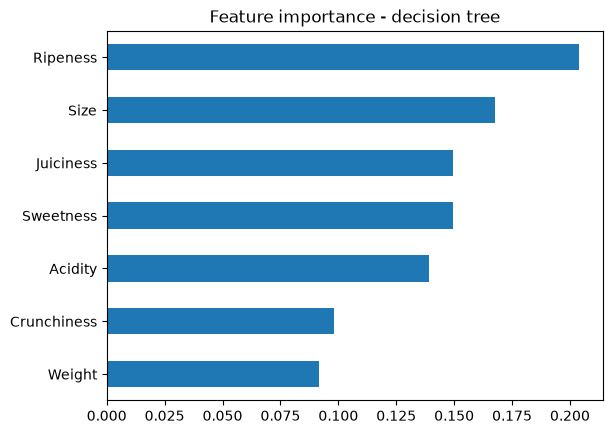

In [35]:
importance = pd.Series(tree.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importance.round(3))

importance.plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Feature importance - decision tree')
plt.show()

L'albero senza limiti sembra imparare a memoria. Per vederlo meglio disegno la **validation curve**: sull'asse x la complessità del modello (la profondità massima dell'albero, da 1 a 20), sull'asse y l'errore (1 - accuracy).

Per non usare il test set nella scelta della profondità, la curva la calcolo con la **cross-validation a 5 fold sul solo training set**: per ogni profondità l'albero viene allenato 5 volte, ogni volta su 4/5 del training e valutato sul quinto rimanente. Il test set lo uso una volta sola, alla fine, sulla profondità scelta.

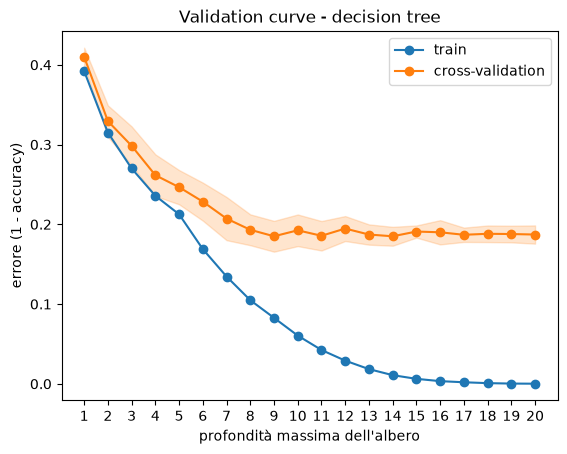

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
train,0.392,0.315,0.270,0.236,0.213,0.169,0.135,0.105,0.083,0.060,0.042,0.029,0.018,0.011,0.006,0.003,0.002,0.001,0.000,0.000
cross-validation,0.410,0.329,0.298,0.262,0.247,0.228,0.207,0.193,0.185,0.193,0.186,0.195,0.187,0.185,0.191,0.190,0.187,0.188,0.188,0.187
dev. std cv,0.011,0.020,0.024,0.026,0.021,0.024,0.027,0.019,0.019,0.020,0.018,0.016,0.013,0.012,0.008,0.015,0.009,0.010,0.010,0.011


In [36]:
from sklearn.model_selection import validation_curve
from sklearn.metrics import accuracy_score

profondita = np.arange(1, 21)
score_train, score_cv = validation_curve(
    DecisionTreeClassifier(random_state=42), X_train, y_train,
    param_name='max_depth', param_range=profondita, cv=5, scoring='accuracy')

# errore medio sui 5 fold
errore_train = 1 - score_train.mean(axis=1)
errore_cv = 1 - score_cv.mean(axis=1)
dev_cv = score_cv.std(axis=1)

plt.plot(profondita, errore_train, marker='o', label='train')
plt.plot(profondita, errore_cv, marker='o', label='cross-validation')
plt.fill_between(profondita, errore_cv - dev_cv, errore_cv + dev_cv, alpha=0.2, color='tab:orange')
plt.xticks(profondita)
plt.xlabel("profondità massima dell'albero")
plt.ylabel('errore (1 - accuracy)')
plt.title('Validation curve - decision tree')
plt.legend()
plt.show()

pd.DataFrame({'train': errore_train, 'cross-validation': errore_cv, 'dev. std cv': dev_cv}, index=profondita).round(3).T

In [37]:
profondita_migliore = profondita[np.argmin(errore_cv)]
print('profondità con errore di cross-validation più basso:', profondita_migliore)

# unico controllo sul test set
tree_limitato = DecisionTreeClassifier(max_depth=profondita_migliore, random_state=42).fit(X_train, y_train)
print('errore sul test:', round(1 - accuracy_score(y_test, tree_limitato.predict(X_test)), 3))
print(classification_report(y_test, tree_limitato.predict(X_test)))

profondità con errore di cross-validation più basso: 9
errore sul test: 0.215
              precision    recall  f1-score   support

           0       0.77      0.80      0.79       399
           1       0.80      0.77      0.78       401

    accuracy                           0.79       800
   macro avg       0.79      0.79      0.78       800
weighted avg       0.79      0.79      0.78       800



Fino a profondità 8-9 l'errore scende sia sul train sia in cross-validation: l'albero sta imparando qualcosa di vero. Da lì in poi l'errore di cross-validation resta fermo intorno al 19%, mentre quello sul train continua a scendere fino a zero: ogni livello in più serve solo a memorizzare il training set. Questo è l'overfitting.

Il minimo è a profondità 9 (18.5%), ma da 8 a 20 le differenze stanno dentro la variabilità tra un fold e l'altro (la banda arancione). Sul test l'albero con profondità 9 sbaglia il 21.5%, in linea con l'albero senza limiti (20%): limitare la profondità non migliora le prestazioni, rende solo il modello molto più semplice a parità di errore. Il decision tree resta comunque sotto la logistic regression con feature polinomiali (12% di errore).

Per confrontare i tre modelli in un colpo solo uso la **ROC curve**: mostra quante mele buone il modello riconosce (true positive rate) contro quante cattive scambia per buone (false positive rate), al variare della soglia di decisione. Più la curva sta in alto a sinistra meglio è, e l'area sotto la curva (AUC) lo riassume in un numero: 0.5 è come tirare a caso, 1 è perfetto.

Calcolo l'AUC anche sul training set: se è molto più alta che sul test, il modello sta overfittando.

logistic semplice - AUC train: 0.827 - AUC test: 0.812
logistic grado 3 - AUC train: 0.973 - AUC test: 0.955
decision tree - AUC train: 1.0 - AUC test: 0.8


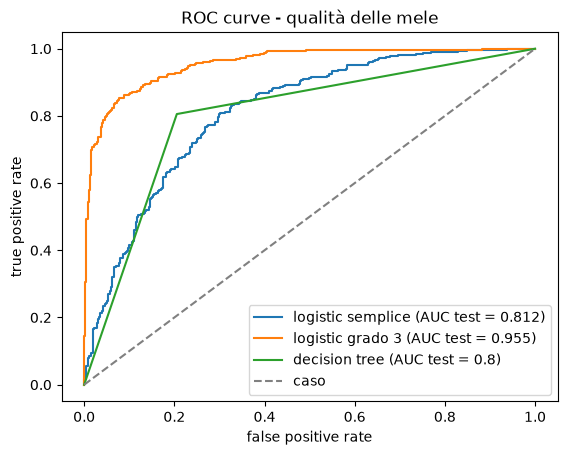

In [38]:
from sklearn.metrics import roc_curve, roc_auc_score

# riprendo anche la logistic regression semplice per il confronto
logistic_semplice = LogisticRegression(max_iter=1000).fit(X_train, y_train)

modelli = {
    'logistic semplice': logistic_semplice,
    'logistic grado 3': logistic_regressor,
    'decision tree': tree,
}

for nome, modello in modelli.items():
    prob_test = modello.predict_proba(X_test)[:, 1]
    prob_train = modello.predict_proba(X_train)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob_test)
    auc_test = roc_auc_score(y_test, prob_test)
    auc_train = roc_auc_score(y_train, prob_train)
    plt.plot(fpr, tpr, label=nome + ' (AUC test = ' + str(round(auc_test, 3)) + ')')
    print(nome, '- AUC train:', round(auc_train, 3), '- AUC test:', round(auc_test, 3))

plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='caso')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('ROC curve - qualità delle mele')
plt.legend()
plt.show()

La logistic regression con feature polinomiali è nettamente la migliore (AUC 0.955 sul test) e non overfitta: sul train fa 0.973, quasi uguale. Il decision tree invece ha AUC **1.0 sul train e 0.80 sul test**: ha imparato a memoria il training set e generalizza peggio. La sua curva è fatta di due soli segmenti dritti: un albero senza limiti di profondità dà come probabilità solo 0 o 1, quindi esiste una sola soglia e un solo punto sulla curva.

# K-Means Clustering

Eccoci al K-Means Clustering, il più utilizzato algoritimo tra quelli non supervisionati.

Per prima cosa bisogna eliminare la label perché, come sai, il K-Means Clustering è un algoritmo non supervisionato e non deve quindi averla:

In [39]:
clustering_dataset = classification_dataset.drop(columns=['Quality'])

Prova a trainare il modello usando l'algoritmo in oggetto, il procedimento è sempre simile a quanto visto in precedenza. Prova a settare dapprima il numero dei cluster a due (in quanto sappiamo che il dataset contiene mele buone o non buone):

In [40]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
kmeans.fit(clustering_dataset)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 7)","[[-1.

Effettua quindi una predizione e vedi a che qualità corrisponde la mela che hai dato in input al modello:

In [41]:
# una mela grande, dolce, succosa e matura
mela = pd.DataFrame([[1.5, 0.5, 2.0, 1.0, 2.0, 1.0, 0.0]], columns=clustering_dataset.columns)
print('cluster assegnato:', kmeans.predict(mela)[0])

# per capire cosa vuol dire quel cluster lo confronto con la qualità vera
pd.crosstab(kmeans.labels_, classification_dataset['Quality'].map({1: 'good', 0: 'bad'}), rownames=['cluster'])

cluster assegnato: 1


Quality,bad,good
cluster,,
0,1314,1015
1,682,989


A che cluster è stata assegnata la mela, è buona o cattiva?
Che succede se invece provi a settare il numero di cluster a tre? Testa questo scenario e rifai la predizione, magari potresti scoprire che in realtà ci sono anche delle mele di qualità intermedia!

In [42]:
kmeans_3 = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_3.fit(clustering_dataset)

print('cluster assegnato:', kmeans_3.predict(mela)[0])
pd.crosstab(kmeans_3.labels_, classification_dataset['Quality'].map({1: 'good', 0: 'bad'}), rownames=['cluster'])

cluster assegnato: 1


Quality,bad,good
cluster,,
0,1036,511
1,493,761
2,467,732


**Risposta:** con 2 cluster la mela finisce nel cluster 1, ma i cluster non coincidono con buone/cattive: il cluster 1 ha 989 buone e 682 cattive (59% buone), il cluster 0 è quasi metà e metà. Quindi posso dire solo che la mela è "probabilmente buona", poco più del caso. Con 3 cluster esce un gruppo con il 67% di mele cattive (cluster 0), mentre gli altri due sono simili tra loro (circa 61% buone): nessun gruppo si distingue come "qualità intermedia". K-Means raggruppa le mele per caratteristiche fisiche simili, e queste non bastano a separare la qualità. Trova dei gruppi, ma cosa significano va verificato con la label.

Due e tre cluster li ho scelti a priori. Per vedere quale numero suggeriscono i dati uso il **metodo del gomito**: alleno K-Means con k da 1 a 10 e guardo l'inertia (la distanza totale dei punti dal centro del proprio cluster). Il k giusto è dove la curva smette di scendere bruscamente.

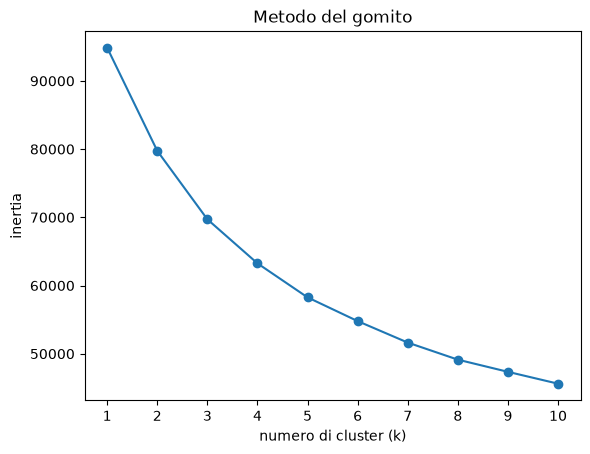

2    -15.9
3    -12.6
4     -9.3
5     -7.9
6     -6.0
7     -5.7
8     -4.8
9     -3.6
10    -3.7
dtype: float64


In [43]:
inertia = []
k_valori = range(1, 11)

for k in k_valori:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(clustering_dataset)
    inertia.append(km.inertia_)

plt.plot(k_valori, inertia, marker='o')
plt.xticks(k_valori)
plt.xlabel('numero di cluster (k)')
plt.ylabel('inertia')
plt.title('Metodo del gomito')
plt.show()

# di quanto scende l'inertia passando da k a k+1
print(pd.Series(inertia, index=k_valori).pct_change().mul(100).round(1).dropna())

Non c'è un gomito netto: la curva scende in modo graduale (-16% da 1 a 2, -13% da 2 a 3, -9% da 3 a 4, poi sempre meno). Se dovessi scegliere direi 3, ma il fatto che il gomito non si veda è coerente con quello visto sopra: le mele non formano gruppi naturali ben separati, quindi K-Means non è lo strumento giusto per decidere la qualità. Per quello serve un modello supervisionato come la logistic regression.

# Time Series

L'ultimo tema del progetto è quello delle time series: se ci hai fatto caso, il dataset che hai utilizzato per la regressione è in realtà una time series a cui, per il problema di regressione stesso, è stata eliminata l'informazione sul tempo in quanto non utile in quello use case. Adesso è tempo di riprenderla!
In questo scenario vogliamo provare a **capire come i gross income evolvono nel tempo**, quindi prendi il dataset originale, ovvero *regression_raw_dataset* ed elimina tutte le colonne, tenendo solo "Date" e "gross income" e avendo cura di chiamare *timeseries_dataset* il nuovo dataset:

In [44]:
timeseries_dataset = regression_raw_dataset[['Date', 'gross income']].copy()
timeseries_dataset['Date'] = pd.to_datetime(timeseries_dataset['Date'])

Dai un rapido sguardo al nuovo dataset creato, per assicurarti che sia tutto ok:

In [45]:
timeseries_dataset.head(100)

,Date,gross income
0,2019-01-05,26.1415
1,2019-03-08,3.8200
2,2019-03-03,16.2155
3,2019-01-27,23.2880
4,2019-02-08,30.2085
...,...,...
95,2019-03-08,4.8580
96,2019-03-29,43.9350
97,2019-02-09,3.7350
98,2019-03-23,7.9125


Ci sono più vendite nello stesso giorno, quindi sommo il gross income per giorno e ottengo una serie con un valore al giorno. Il file originale non è in ordine di data (si vede nella tabella sopra), quindi ordino la serie in modo esplicito:

89 giorni, dal 2019-01-01 al 2019-03-30


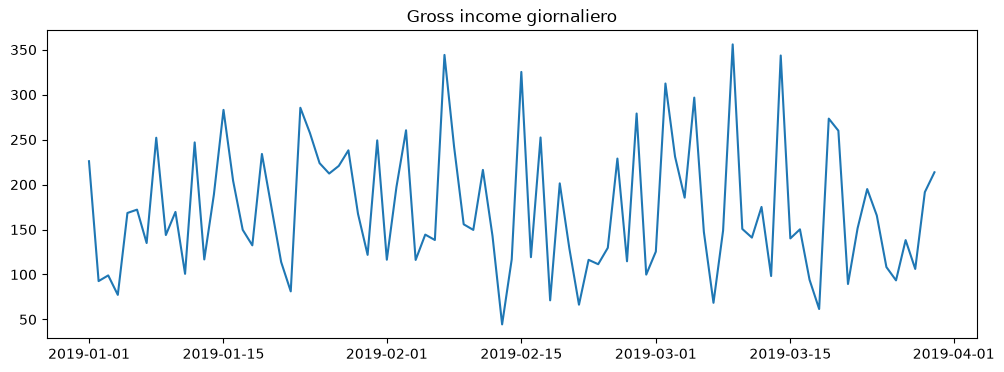

In [46]:
daily = timeseries_dataset.groupby('Date')['gross income'].sum().reset_index()
daily = daily.sort_values('Date').reset_index(drop=True)
daily['giorno'] = (daily['Date'] - daily['Date'].min()).dt.days
print(len(daily), 'giorni, dal', daily['Date'].min().date(), 'al', daily['Date'].max().date())

plt.figure(figsize=(12, 4))
plt.plot(daily['Date'], daily['gross income'])
plt.title('Gross income giornaliero')
plt.show()

A questo punto prova a utilizzare la **linear regression** su questa serie temporale, nello stesso modo di quanto già fatto in precedenza:

In [47]:
# su una serie storica lo split non va fatto a caso: shuffle=False tiene l'ordine delle date,
# quindi alleno sul passato (primo 80%) e testo sugli ultimi giorni (ultimo 20%)
train, test = train_test_split(daily, test_size=0.2, shuffle=False)
print('train:', train['Date'].min().date(), '->', train['Date'].max().date(), '(' + str(len(train)) + ' giorni)')
print('test: ', test['Date'].min().date(), '->', test['Date'].max().date(), '(' + str(len(test)) + ' giorni)')

regressor = LinearRegression()
regressor.fit(train[['giorno']], train['gross income'])
print('variazione stimata al giorno:', round(regressor.coef_[0], 2))

train: 2019-01-01 -> 2019-03-12 (71 giorni)
test:  2019-03-13 -> 2019-03-30 (18 giorni)
variazione stimata al giorno: 0.15


E vai a controllare le solite metriche, cioè MSE ed MAE:

In [48]:
y_pred = regressor.predict(test[['giorno']])
MSE = mean_squared_error(test['gross income'], y_pred)
MAE = mean_absolute_error(test['gross income'], y_pred)

print('MSE =', MSE, '\nMAE =', MAE)
print('baseline MAE (media del train) =', mean_absolute_error(test['gross income'], np.full(len(test), train['gross income'].mean())))

MSE = 5854.847526438536 
MAE = 65.30463582886205
baseline MAE (media del train) = 63.174847809076674


Ti renderai conto che probabilmente non sono così elevati come in precedenza, questo perché la regressione lineare sulle time series spesso fallisce e, come già visto nella teoria, c'è bisogno di altri modelli più perfomanti.

Un solo split 80/20 vuol dire giudicare il modello su 18 giorni soltanto. Per avere una stima più affidabile uso **TimeSeriesSplit**, la cross-validation pensata per le serie storiche: divide la serie in 5 finestre successive e ogni volta allena su tutti i giorni fino a un certo punto e testa sui 14 giorni dopo. A differenza della cross-validation classica, il test è sempre nel futuro rispetto al train, quindi niente leakage.

Per ogni finestra confronto il modello con la baseline (la media del train di quella finestra):

In [49]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

def valuta_con_timeseriessplit(modello, dati, features):
    risultati = []
    for fold, (idx_train, idx_test) in enumerate(tscv.split(dati), start=1):
        train_cv, test_cv = dati.iloc[idx_train], dati.iloc[idx_test]
        modello.fit(train_cv[features], train_cv['gross income'])
        previsione = modello.predict(test_cv[features])
        baseline = np.full(len(test_cv), train_cv['gross income'].mean())
        risultati.append({
            'fold': fold,
            'train fino al': train_cv['Date'].max().date(),
            'test': str(test_cv['Date'].min().date()) + ' -> ' + str(test_cv['Date'].max().date()),
            'MAE modello': round(mean_absolute_error(test_cv['gross income'], previsione), 1),
            'MAE baseline': round(mean_absolute_error(test_cv['gross income'], baseline), 1),
        })
    risultati = pd.DataFrame(risultati).set_index('fold')
    print('MAE medio modello:', round(risultati['MAE modello'].mean(), 1), '- MAE medio baseline:', round(risultati['MAE baseline'].mean(), 1))
    return risultati

valuta_con_timeseriessplit(LinearRegression(), daily, ['giorno'])

MAE medio modello: 67.9 - MAE medio baseline: 64.3


,train fino al,test,MAE modello,MAE baseline
fold,,,,
1,2019-01-19,2019-01-20 -> 2019-02-02,54.8,56.1
2,2019-02-02,2019-02-03 -> 2019-02-16,82.1,69.3
3,2019-02-16,2019-02-17 -> 2019-03-02,77.9,73.0
4,2019-03-02,2019-03-03 -> 2019-03-16,63.6,63.6
5,2019-03-16,2019-03-17 -> 2019-03-30,61.3,59.4


pendenza: -0.11 al giorno, su una media di 172.8


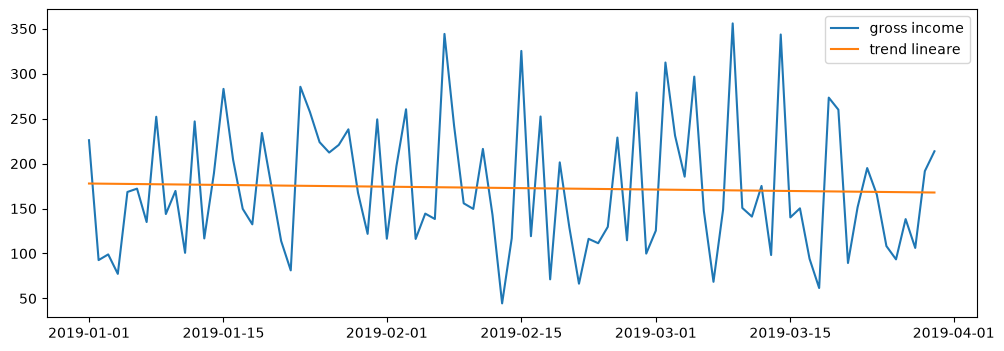

In [50]:
# trend su tutti i 3 mesi
trend = LinearRegression().fit(daily[['giorno']], daily['gross income'])
print('pendenza:', round(trend.coef_[0], 2), 'al giorno, su una media di', round(daily['gross income'].mean(), 1))

plt.figure(figsize=(12, 4))
plt.plot(daily['Date'], daily['gross income'], label='gross income')
plt.plot(daily['Date'], trend.predict(daily[['giorno']]), label='trend lineare')
plt.legend()
plt.show()

**Risposta:** sugli ultimi 18 giorni la regressione lineare ha MAE 65.3, peggio della semplice media del training (63.2). Con TimeSeriesSplit il risultato si conferma su tutto il periodo: MAE medio 67.9 contro 64.3 della baseline, peggio in 3 finestre su 5. Su tutti e tre i mesi la pendenza è -0.11 al giorno su una media di 172.8 al giorno: in tre mesi la retta scende di circa 10, cioè praticamente niente. Per il cliente la risposta è che gli utili sono **stazionari**, né in crescita né in calo, con oscillazioni giornaliere molto forti (deviazione standard di circa 73). Limite: tre mesi sono pochi per parlare di trend e non permettono di vedere una stagionalità annuale.

# Time Series con XGBoost (opzionale)

A proposito di modelli più performanti per le time series, ricordi XGBoost? Se ti va, puoi provare a impiegare quest'ultimo per costruire il modello. **Questa sezione è opzionale e non necessaria per superare il progetto.**

In [51]:
from xgboost import XGBRegressor

# feature: giorno della settimana e valori dei giorni precedenti
daily['giorno_settimana'] = daily['Date'].dt.dayofweek
daily['ieri'] = daily['gross income'].shift(1)
daily['settimana_prima'] = daily['gross income'].shift(7)
xgb_data = daily.dropna()

# stesso split cronologico di prima
train, test = train_test_split(xgb_data, test_size=0.2, shuffle=False)
print('train:', train['Date'].min().date(), '->', train['Date'].max().date(), '| test:', test['Date'].min().date(), '->', test['Date'].max().date())
features = ['giorno', 'giorno_settimana', 'ieri', 'settimana_prima']

xgb = XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05)
xgb.fit(train[features], train['gross income'])

y_pred = xgb.predict(test[features])
MSE = mean_squared_error(test['gross income'], y_pred)
MAE = mean_absolute_error(test['gross income'], y_pred)
print('MSE =', MSE, '\nMAE =', MAE)
print('baseline MAE =', mean_absolute_error(test['gross income'], np.full(len(test), train['gross income'].mean())))

train: 2019-01-08 -> 2019-03-13 | test: 2019-03-14 -> 2019-03-30
MSE = 6598.938253702646 
MAE = 62.63751805922564
baseline MAE = 63.14636425339366


In [52]:
# stessa cross-validation per serie storiche usata con la regressione lineare
valuta_con_timeseriessplit(XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05), xgb_data, features)

MAE medio modello: 62.9 - MAE medio baseline: 64.2


,train fino al,test,MAE modello,MAE baseline
fold,,,,
1,2019-01-24,2019-01-25 -> 2019-02-06,46.6,47.1
2,2019-02-06,2019-02-07 -> 2019-02-19,70.7,74.3
3,2019-02-19,2019-02-20 -> 2019-03-04,68.6,69.0
4,2019-03-04,2019-03-05 -> 2019-03-17,70.2,72.2
5,2019-03-17,2019-03-18 -> 2019-03-30,58.4,58.2


lun    150.4
mar    188.6
mer    160.2
gio    166.1
ven    160.9
sab    205.6
dom    176.4
Name: gross income, dtype: float64


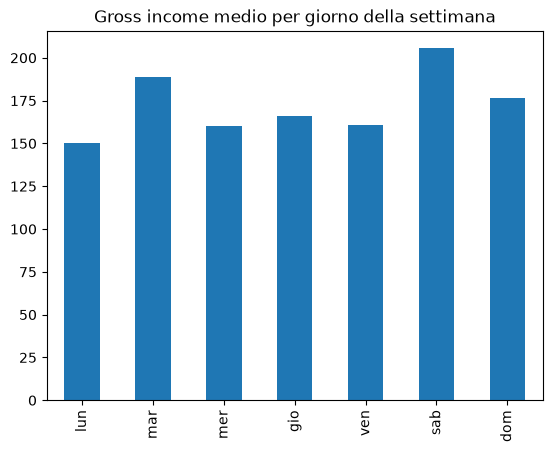

In [53]:
giorni = ['lun', 'mar', 'mer', 'gio', 'ven', 'sab', 'dom']
media_giorno = daily.groupby('giorno_settimana')['gross income'].mean()
media_giorno.index = giorni
print(media_giorno.round(1))

media_giorno.plot(kind='bar')
plt.title('Gross income medio per giorno della settimana')
plt.show()

**Risposta:** XGBoost arriva a MAE 62.6 contro 63.1 della baseline, praticamente lo stesso risultato. Con TimeSeriesSplit va un po' meglio della regressione lineare: batte la baseline in 4 finestre su 5, ma con un MAE medio di 62.9 contro 64.2, cioè circa il 2% in meno. È un miglioramento troppo piccolo per usarlo come previsione. Con 82 giorni utilizzabili (i primi 7 li perdo per costruire il valore della settimana prima) non c'è abbastanza storia per un modello del genere. L'unica regolarità che si vede è il giorno della settimana: il sabato in media fa 205.6 di gross income, il lunedì 150.4. Per il cliente questa è un'informazione più utile della previsione, per esempio per organizzare personale e scorte.

# Ottimizzazione degli iperparametri con grid search

I parametri di XGBoost sopra li ho scelti a mano. Provo a trovarli in automatico con **GridSearchCV**, che allena il modello su tutte le combinazioni di una griglia e tiene quella con l'errore più basso in cross-validation. Due accortezze per non avere leakage:
- la grid search gira **solo sul train** (primo 80% dei giorni), con **TimeSeriesSplit** come cross-validation;
- il **test** (ultimi giorni) lo uso una volta sola, alla fine, sul modello scelto.

Iperparametri che faccio variare: numero di alberi (`n_estimators`), profondità (`max_depth`), velocità di apprendimento (`learning_rate`) e quota di giorni usata da ogni albero (`subsample`).

In [54]:
from sklearn.model_selection import GridSearchCV, cross_val_score

griglia_xgb = {
    'n_estimators': [50, 100, 200, 400],
    'max_depth': [1, 2, 3, 4],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
}

grid_xgb = GridSearchCV(XGBRegressor(random_state=42), griglia_xgb, cv=TimeSeriesSplit(n_splits=5),
                        scoring='neg_mean_absolute_error', n_jobs=-1)
grid_xgb.fit(train[features], train['gross income'])

print('combinazioni provate:', len(grid_xgb.cv_results_['params']))
print('migliori iperparametri:', grid_xgb.best_params_)
print('MAE in cross-validation:', round(-grid_xgb.best_score_, 1))

# per confronto: i parametri scelti a mano e la baseline, sulla stessa cross-validation
cv_train = TimeSeriesSplit(n_splits=5)
mae_a_mano = -cross_val_score(XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05), train[features], train['gross income'],
                              cv=cv_train, scoring='neg_mean_absolute_error').mean()
mae_baseline_cv = np.mean([mean_absolute_error(train['gross income'].iloc[te], np.full(len(te), train['gross income'].iloc[tr].mean()))
                           for tr, te in cv_train.split(train)])
print('MAE in cross-validation con i parametri scelti a mano:', round(mae_a_mano, 1))
print('MAE in cross-validation della baseline:', round(mae_baseline_cv, 1))

combinazioni provate: 96
migliori iperparametri: {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 50, 'subsample': 0.8}
MAE in cross-validation: 67.4


MAE in cross-validation con i parametri scelti a mano: 82.2
MAE in cross-validation della baseline: 66.7


La grid search abbassa l'errore in cross-validation da 82.2 a 67.4 rispetto ai parametri scelti a mano: quelli erano troppo complessi e overfittavano. Però la combinazione che vince è la più prudente di tutta la griglia (`learning_rate` 0.01 e solo 50 alberi), cioè un modello che si sposta pochissimo dalla media, e resta comunque sopra la baseline (66.7). In pratica la grid search ha "scoperto" da sola che in questi dati non c'è molto da imparare.

Provo quindi anche a cambiare modello, con un **Random Forest**, ottimizzato allo stesso modo:

In [55]:
from sklearn.ensemble import RandomForestRegressor

griglia_rf = {
    'n_estimators': [100, 300],
    'max_depth': [2, 3, 5, None],
    'min_samples_leaf': [1, 3, 5],
}

grid_rf = GridSearchCV(RandomForestRegressor(random_state=42), griglia_rf, cv=TimeSeriesSplit(n_splits=5),
                       scoring='neg_mean_absolute_error', n_jobs=-1)
grid_rf.fit(train[features], train['gross income'])

print('migliori iperparametri:', grid_rf.best_params_)
print('MAE in cross-validation:', round(-grid_rf.best_score_, 1))

migliori iperparametri: {'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 100}
MAE in cross-validation: 66.2


Infine il controllo sul test, una volta sola per ogni modello:

In [56]:
confronto = pd.DataFrame({
    'MAE test': {
        'baseline (media del train)': mean_absolute_error(test['gross income'], np.full(len(test), train['gross income'].mean())),
        'XGBoost parametri a mano': mean_absolute_error(test['gross income'], xgb.predict(test[features])),
        'XGBoost grid search': mean_absolute_error(test['gross income'], grid_xgb.predict(test[features])),
        'Random Forest grid search': mean_absolute_error(test['gross income'], grid_rf.predict(test[features])),
    }
}).round(1)
confronto['vs baseline'] = (confronto['MAE test'] / confronto.loc['baseline (media del train)', 'MAE test'] - 1).mul(100).round(1).astype(str) + '%'
confronto

,MAE test,vs baseline
baseline (media del train),63.1,0.0%
XGBoost parametri a mano,62.6,-0.8%
XGBoost grid search,63.1,0.0%
Random Forest grid search,61.6,-2.4%


**Risposta:** la grid search migliora la scelta dei parametri (soprattutto evita l'overfitting dei parametri scelti a mano), ma non può creare un segnale che nei dati non c'è. XGBoost ottimizzato finisce praticamente sulla baseline (63.1 contro 63.1). Sul test quello con i parametri a mano sembra un po' meglio (62.6), ma su 17 giorni la differenza è rumore: in cross-validation, che media 5 finestre, gli stessi parametri fanno 82.2, molto peggio di tutti. Il modello migliore è il Random Forest ottimizzato, con MAE 61.6 sul test, il 2.4% in meno della baseline, e anche in cross-validation è l'unico sotto la baseline (66.2 contro 66.7). È un miglioramento reale ma piccolo, su soli 17 giorni di test.

Con 89 giorni di dati e nessuna variabile esterna, più tuning o modelli più complessi difficilmente cambierebbero il quadro. Per prevedere meglio servirebbero più dati (almeno un anno, per vedere la stagionalità) o informazioni in più, come promozioni, festività e meteo.

# ARIMA

Come ultima prova uso **ARIMA**, il modello classico per le serie storiche. A differenza di XGBoost e Random Forest non usa feature costruite da me: prevede ogni giorno solo a partire dai valori passati della serie stessa. Ha tre parametri:
- **p**: quanti giorni passati usa (parte autoregressiva);
- **d**: quante volte differenzia la serie (valore di oggi meno valore di ieri) per renderla stazionaria;
- **q**: quanti errori di previsione passati usa (parte a media mobile).

Per poterlo confrontare con gli altri modelli uso esattamente lo stesso train e lo stesso test. Prima controllo se la serie è stazionaria con il test di Dickey-Fuller (ADF), che serve a scegliere d, e guardo l'autocorrelazione, cioè quanto il valore di oggi è legato a quello dei giorni prima.

p-value test ADF: 1.225984793395411e-13
p-value test di Ljung-Box (primi 7 lag): 0.779


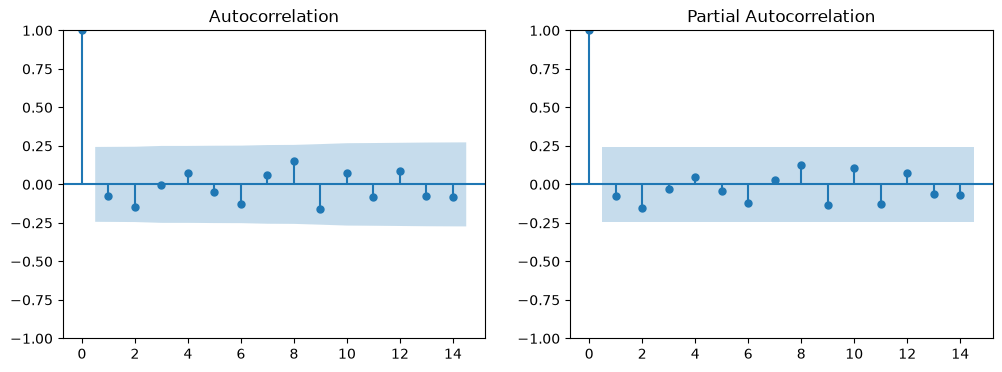

In [57]:
import warnings
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

# stessa serie, train e test degli altri modelli, con frequenza giornaliera
serie_train = train.set_index('Date')['gross income'].asfreq('D')
serie_test = test.set_index('Date')['gross income'].asfreq('D')

print('p-value test ADF:', adfuller(serie_train, result_object=False)[1])
print('p-value test di Ljung-Box (primi 7 lag):', round(acorr_ljungbox(serie_train, lags=[7])['lb_pvalue'].iloc[0], 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(serie_train, lags=14, ax=ax[0])
plot_pacf(serie_train, lags=14, ax=ax[1])
plt.show()

Il p-value del test ADF è praticamente zero (1e-13), quindi la serie è già stazionaria e non serve differenziarla: uso **d = 0**. Il test di Ljung-Box invece ha p-value 0.78, quindi non posso escludere che la serie sia **rumore bianco**, cioè che il valore di un giorno non dipenda da quelli dei giorni prima. Lo confermano i due grafici: tutte le barre restano dentro la fascia azzurra (la più alta vale 0.16 contro un limite di circa 0.24). Anche al lag 7 non si vede niente (0.06), quindi la differenza tra sabato e lunedì vista sopra è troppo debole per comparire come autocorrelazione in 9 settimane di dati.

Già da qui mi aspetto che ARIMA abbia poco da sfruttare. Scelgo comunque p e q in automatico, con una piccola grid search sull'AIC (un indice che premia il modello che spiega bene i dati ma penalizza i parametri in più):

In [58]:
# scelgo p e q provando tutte le combinazioni da 0 a 3 e tenendo quella con l'AIC più basso
warnings.filterwarnings('ignore')
risultati = []
for p in range(4):
    for q in range(4):
        modello = ARIMA(serie_train, order=(p, 0, q)).fit()
        risultati.append({'ordine': (p, 0, q), 'AIC': round(modello.aic, 1)})
risultati = pd.DataFrame(risultati).sort_values('AIC')
risultati.head()

,ordine,AIC
0,"(0, 0, 0)",745.9
10,"(2, 0, 2)",746.7
1,"(0, 0, 1)",747.4
4,"(1, 0, 0)",747.5
2,"(0, 0, 2)",748.0


L'ordine con l'AIC più basso è **ARIMA(0,0,0)**, cioè un modello senza parte autoregressiva e senza media mobile: prevede sempre una costante, che è la media del train. In pratica ARIMA arriva da solo alla stessa conclusione della baseline. Il secondo è ARIMA(2,0,2), con un AIC quasi uguale (746.7 contro 745.9).

Valuto i tre ordini migliori, più un ARIMA(1,1,1) con differenziazione come controprova, in due modi: prevedendo tutti i 17 giorni di test in un colpo solo, e un giorno alla volta, aggiornando il modello con il valore vero di ieri (come fa XGBoost con la feature `ieri`). Aggiungo anche la cross-validation con TimeSeriesSplit sul train.

In [59]:
def mae_arima(ordine):
    modello = ARIMA(serie_train, order=ordine).fit()
    # previsione di tutti i giorni di test in un colpo solo, senza vedere i valori veri
    in_avanti = modello.forecast(len(serie_test))
    # previsione un giorno alla volta: ogni giorno il modello conosce il valore vero di ieri, come XGBoost
    giorno_per_giorno = modello.append(serie_test, refit=False).predict(start=serie_test.index[0], end=serie_test.index[-1])

    # cross-validation con TimeSeriesSplit sul train, come per gli altri modelli
    mae_cv = []
    for idx_train, idx_test in TimeSeriesSplit(n_splits=5).split(serie_train):
        m = ARIMA(serie_train.iloc[idx_train], order=ordine).fit()
        prev = m.append(serie_train.iloc[idx_test], refit=False).predict(start=serie_train.index[idx_test[0]], end=serie_train.index[idx_test[-1]])
        mae_cv.append(mean_absolute_error(serie_train.iloc[idx_test], prev))

    return {'MAE cross-validation': round(np.mean(mae_cv), 1),
            'MAE test (17 giorni in avanti)': round(mean_absolute_error(serie_test, in_avanti), 1),
            'MAE test (un giorno alla volta)': round(mean_absolute_error(serie_test, giorno_per_giorno), 1)}

# i tre ordini migliori per AIC, più un ARIMA(1,1,1) con differenziazione per confronto
ordini = list(risultati['ordine'].head(3)) + [(1, 1, 1)]
pd.DataFrame({str(o): mae_arima(o) for o in ordini}).T

,MAE cross-validation,MAE test (17 giorni in avanti),MAE test (un giorno alla volta)
"(0, 0, 0)",66.7,63.1,63.1
"(2, 0, 2)",67.2,69.2,68.5
"(0, 0, 1)",67.3,62.6,62.8
"(1, 1, 1)",66.5,62.8,63.7


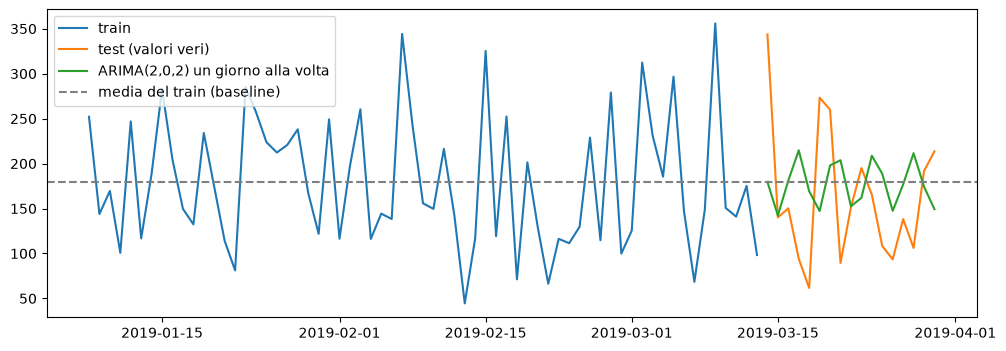

In [60]:
migliore = ARIMA(serie_train, order=(2, 0, 2)).fit()
previsione = migliore.append(serie_test, refit=False).predict(start=serie_test.index[0], end=serie_test.index[-1])

plt.figure(figsize=(12, 4))
plt.plot(serie_train.index, serie_train, label='train')
plt.plot(serie_test.index, serie_test, label='test (valori veri)')
plt.plot(serie_test.index, previsione, label='ARIMA(2,0,2) un giorno alla volta')
plt.axhline(serie_train.mean(), color='grey', linestyle='--', label='media del train (baseline)')
plt.legend()
plt.show()

In [61]:
# tabella finale con tutti i modelli provati sulla serie storica
confronto.loc['ARIMA(0,0,0) = media', 'MAE test'] = mae_arima((0, 0, 0))['MAE test (un giorno alla volta)']
confronto.loc['ARIMA(2,0,2)', 'MAE test'] = mae_arima((2, 0, 2))['MAE test (un giorno alla volta)']
confronto['vs baseline'] = (confronto['MAE test'] / confronto.loc['baseline (media del train)', 'MAE test'] - 1).mul(100).round(1).astype(str) + '%'
confronto

,MAE test,vs baseline
baseline (media del train),63.1,0.0%
XGBoost parametri a mano,62.6,-0.8%
XGBoost grid search,63.1,0.0%
Random Forest grid search,61.6,-2.4%
"ARIMA(0,0,0) = media",63.1,0.0%
"ARIMA(2,0,2)",68.5,8.6%


**Risposta:** ARIMA non migliora le prestazioni. Il modello scelto dall'AIC, ARIMA(0,0,0), coincide con la baseline (MAE 63.1 sul test, 66.7 in cross-validation). Il secondo per AIC, ARIMA(2,0,2), cerca di seguire le oscillazioni e peggiora: 68.5 sul test, l'8.6% in più della baseline. Gli altri ordini finiscono tutti tra 62.6 e 63.7 sul test e tra 66.5 e 67.3 in cross-validation, cioè attorno alla baseline, e quelle differenze su 17 giorni sono rumore.

Il motivo lo dicono già i test fatti all'inizio: la serie è stazionaria e non ha autocorrelazione (Ljung-Box p = 0.78), quindi i valori passati non dicono niente sul giorno dopo, e ARIMA usa solo quelli. È lo stesso limite trovato con XGBoost e Random Forest, visto da un'altra angolazione. Su tutta la serie storica il modello migliore resta il Random Forest ottimizzato (61.6, -2.4%), e anche quello è un miglioramento piccolo.

Per il cliente la conclusione non cambia: con tre mesi di dati il gross income giornaliero oscilla attorno a una media stabile senza un andamento prevedibile, e la media resta la previsione più affidabile. L'informazione utile è il giorno della settimana (sabato 205.6 contro lunedì 150.4). Per un modello di previsione vero servirebbero almeno un anno di dati, per vedere la stagionalità, e variabili esterne come promozioni, festività e meteo.

# Wrap up

Gran parte delle tecniche di questo progetto non erano nuove per me: le avevo già usate nella tesi della laurea in Economia e Big Data, dove ho analizzato la serie storica di Bitcoin con diversi indicatori, usando anche XGBoost.

Quello che mi porto dietro da questo progetto è soprattutto di metodo:
- **Confrontare sempre il modello con una baseline.** Un MSE di 3.11 sul Rating, da solo, sembra un numero come un altro. Solo confrontandolo con la media (3.08) si vede che il modello non impara niente.
- **Non fidarsi dei dataset "già puliti".** L'ultima riga del dataset delle mele conteneva il nome dell'autore e trasformava Acidity in una colonna di testo.
- **Sulle serie storiche la validazione conta quanto il modello.** XGBoost con i parametri scelti a mano sembrava il migliore sul test (62.6), ma con TimeSeriesSplit era il peggiore (82.2). Su 17 giorni di test una differenza piccola è rumore.
- **Più complessità non crea segnale.** Regressione lineare, XGBoost, Random Forest con grid search e ARIMA arrivano tutti più o meno alla media, perché la serie è stazionaria e senza autocorrelazione. Con una sola serie di tre mesi il limite sono i dati, non il modello, e a quel punto l'informazione utile per il cliente è un'altra: il sabato rende il 37% in più del lunedì.
- **Usare gli strumenti standard.** `OneHotEncoder` produce le stesse colonne su train e test e si inserisce in una pipeline, a differenza di `get_dummies`.